Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

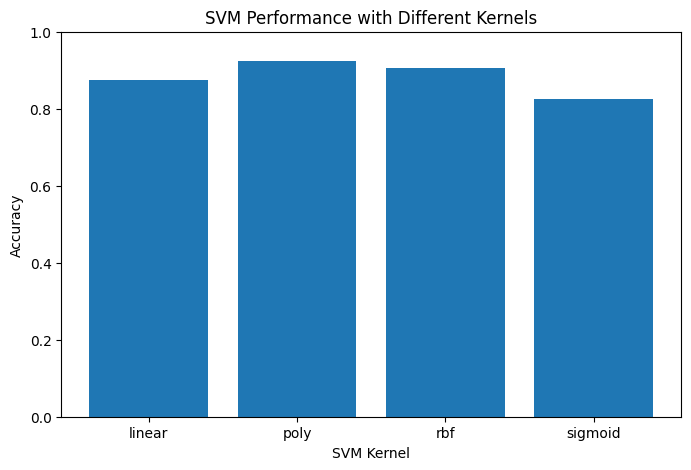


Result:
SVM classification was successfully performed
using Linear, Polynomial, RBF and Sigmoid kernels.


In [1]:
# EXERCISE - 10 (SUPPORT VECTOR MACHINE)

#!/usr/bin/env python
# coding: utf-8

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("/content/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("\nNumerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

kernels = ["linear", "poly", "rbf", "sigmoid"]

results = []

for kernel in kernels:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("svm", SVC(kernel=kernel, random_state=42))
        ]
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append([
        kernel,
        accuracy,
        precision,
        recall,
        f1
    ])

    print("\n======================================")
    print("SVM Kernel:", kernel)
    print("======================================")

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

results_df = pd.DataFrame(
    results,
    columns=[
        "Kernel",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\n\nKernel Comparison:")
print(results_df)

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Kernel"],
    results_df["Accuracy"]
)

plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy")
plt.title("SVM Performance with Different Kernels")
plt.ylim(0, 1)

plt.show()

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

print("\nResult:")
print("SVM classification was successfully performed")
print("using Linear, Polynomial, RBF and Sigmoid kernels.")